# 05. Validation Thresholds and Final Evaluation
**Responsibility:** H Maheshwari (Hardik) -validation thresholds and final evaluation.

**Goal:** Set cutoffs on validation, then measure the fixed choices on the later mixed test period.

**Inputs:** the scaled arrays from notebook 03 and the fitted models from notebook 04.

**Outputs:** final result tables, PR curves, score diagnostics, review-capacity analysis and a summary.

Start in a fresh Python session, Run notebooks 02-04 first if input files are missing. It evaluates the same fixed experiment; it does not tune a new model against test outcomes.

### Files used in this notebook
- **Read from notebook 03:** `data/processed/features.npz` (validation/test inputs and separate labels).
- **Read from notebook 04:** `models/gmm_models.joblib` (the already fitted models).
- **Read for the final summary:** `results/data_quality.json` from 02 and `results/model_settings.json` from 04.
- **Save:** thresholds, evaluation tables, test scores, summary, software versions and six evaluation charts. Each save cell names its exact file.

The report and slides use the numbers produced here. See `FILE_MAP.md` in the main folder for every result and chart.

## Setup for this notebook
Run from the project root or the `notebooks` folder. The next cell finds the root folder, so saved paths work in either case. Each notebook loads the previous stage's saved files. It does not depend on variables left in another notebook's Python session.

`Path` handles folders, `os.chdir` selects the project root, `pd` handles tables, `np` handles numbers, and `plt` draws charts. The `display` and `Image` tools show tables and pictures.

In [1]:
from pathlib import Path
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "requirements.txt").exists(), "Open this notebook from the project folder."
os.chdir(ROOT)
Path("figures").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

import joblib
from sklearn.metrics import precision_recall_curve, auc, confusion_matrix, ConfusionMatrixDisplay

**Files in the next cell:** `data/processed/features.npz`, `models/gmm_models.joblib`.

`read_csv`, `np.load` and `joblib.load` read files. `to_csv`, `write_text`, `savefig`, `np.savez_compressed` and `joblib.dump` save files. The file map explains what each file contains.

In [2]:
assert Path("data/processed/features.npz").exists(), "Run notebook 03 first."
assert Path("models/gmm_models.joblib").exists(), "Run notebook 04 first."
arrays = np.load("data/processed/features.npz", allow_pickle=False)
X_validation_scaled = arrays["X_validation"]
X_test_scaled = arrays["X_test"]
y_validation = arrays["y_validation"]
y_test = arrays["y_test"]
saved_models = joblib.load("models/gmm_models.joblib")
model = saved_models["selected_gmm"]
one_gaussian = saved_models["one_gaussian"]
print("Loaded fixed models and evaluation inputs.")

Loaded fixed models and evaluation inputs.


## 1. Turn density into an anomaly score
**Density** means how strongly the fitted model supports a transaction's location in the input space. A low-density transaction looks less typical of the legitimate training data.

We use: **anomaly score = -log(density)**.

`score_samples` already returns log density, one value per transaction. Putting a minus sign in front makes less usual transactions have **larger** scores.

For a numerical illustration: density 0.01 gives a score about 4.61; density 0.0001 gives about 9.21. The second is less usual under that model. These are teaching numbers, not scores taken from our dataset.

An anomaly score is **not a probability of fraud**. A continuous density can exceed one, so scores can also be negative.

In [3]:
validation_scores = -model.score_samples(X_validation_scaled)
normal_validation_scores = validation_scores[y_validation == 0]

print("First five validation anomaly scores:")
print(validation_scores[:5])

First five validation anomaly scores:
[41.90428372 38.35735395 32.89847696 33.39453481 35.05359906]


**Code explanation:** The first line scores every validation transaction. The second keeps only scores whose validation label is 0. Those known legitimate examples will set our alert cutoff. We have not evaluated test performance yet.

## 2. Choose alert cutoffs using validation data
A **threshold** is a cutoff: create an alert if `score > threshold`.

A **false positive** is a legitimate transaction that receives an alert. A **false-positive rate (FPR)** is false alerts divided by all legitimate transactions.

We try three validation budgets:
- **0.1%:** about 1 false alert per 1,000 legitimate transactions.
- **0.5%:** about 5 per 1,000. This is our illustrative default.
- **1%:** about 10 per 1,000.

For 0.5%, choose the **99.5th percentile** of legitimate validation scores. A percentile is a position in a sorted list: most legitimate scores fall below this cutoff. `method="higher"` chooses an actual score conservatively, helping keep the observed validation false-alert rate within budget.

The default 0.5% is a classroom example chosen before test evaluation, not an operating target from a bank.

**Files in the next cell:** `results/validation_thresholds.csv`.

`read_csv`, `np.load` and `joblib.load` read files. `to_csv`, `write_text`, `savefig`, `np.savez_compressed` and `joblib.dump` save files. The file map explains what each file contains.

In [4]:
budgets = [0.001, 0.005, 0.01]
thresholds = {}
validation_rows = []

for budget in budgets:
    cutoff = np.percentile(normal_validation_scores, 100 * (1 - budget), method="higher")
    thresholds[budget] = float(cutoff)
    observed_fpr = np.mean(normal_validation_scores > cutoff)
    assert observed_fpr <= budget
    validation_rows.append({"Budget (%)": 100*budget, "Threshold": float(cutoff),
        "Validation FPR (%)": 100*observed_fpr,
        "Validation false alerts": int((normal_validation_scores > cutoff).sum())})
    print(f"Budget {100*budget:.1f}%: cutoff {cutoff:.4f}, validation FPR {100*observed_fpr:.4f}%")

default_threshold = thresholds[0.005]
print("All choices are fixed. We can now evaluate the test period.")
pd.DataFrame(validation_rows).to_csv("results/validation_thresholds.csv", index=False)

Budget 0.1%: cutoff 112.9651, validation FPR 0.0988%
Budget 0.5%: cutoff 75.8942, validation FPR 0.4992%
Budget 1.0%: cutoff 68.9345, validation FPR 0.9984%
All choices are fixed. We can now evaluate the test period.


**How to read the output:** The default cutoff is about **75.8942**. A transaction with a score above it gets an alert; a score equal to it does not.

A validation budget controls the observed validation rate. Later test transactions can have a different rate because their patterns can differ. We keep the cutoff fixed rather than changing it to match the test labels.

`np.mean(normal_validation_scores > cutoff)` finds the fraction flagged: Python counts True as 1 and False as 0, so their average is the fraction of alerts.

## 3. Evaluate the later test period
**What we do:** Score the test transactions with the already chosen GMM and threshold.

**Why:** This checks how the fixed choices behave on later data. We do not use these results to choose K or change the threshold.

`predicted_fraud` contains True for an alert and False for no alert. The confusion matrix counts four outcomes:

| Name | Meaning |
|---|---|
| TN: true negative | Legitimate, no alert |
| FP: false positive | Legitimate, alert |
| FN: false negative | Fraud, no alert |
| TP: true positive | Fraud, alert |

In [5]:
test_scores = -model.score_samples(X_test_scaled)
predicted_fraud = test_scores > default_threshold

cm = confusion_matrix(y_test, predicted_fraud, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print("Legitimate with no alert (TN):", tn)
print("Legitimate with an alert (FP):", fp)
print("Fraud missed (FN):", fn)
print("Fraud found (TP):", tp)

Legitimate with no alert (TN): 56500
Legitimate with an alert (FP): 172
Fraud missed (FN): 37
Fraud found (TP): 37


**Code explanation:** `ravel()` reads the 2-by-2 matrix in row order: TN, FP, FN, TP.

**Our result:** We correctly leave 56,500 legitimate transactions unflagged, falsely alert on 172 legitimate transactions, miss 37 frauds, and find 37 frauds.

**Files in the next cell:** `figures/07_confusion.png`.

`read_csv`, `np.load` and `joblib.load` read files. `to_csv`, `write_text`, `savefig`, `np.savez_compressed` and `joblib.dump` save files. The file map explains what each file contains.

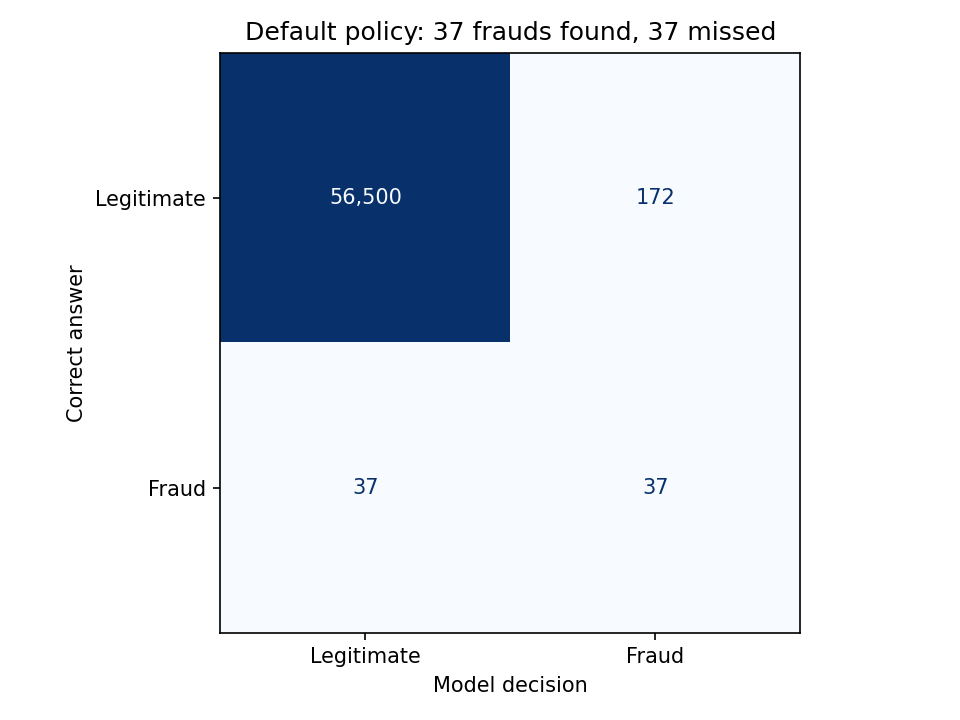

In [6]:
ConfusionMatrixDisplay(cm, display_labels=["Legitimate", "Fraud"]).plot(
    cmap="Blues", values_format=",d", colorbar=False)
plt.xlabel("Model decision")
plt.ylabel("Correct answer")
plt.title("Default policy: 37 frauds found, 37 missed")
plt.tight_layout()
plt.savefig("figures/07_confusion.png", dpi=150)
display(Image(filename="figures/07_confusion.png", width=800))
plt.close()

**Chart explanation:** Rows show the correct class; columns show the model's decision. The top-right box contains false alerts. The bottom-left box contains missed fraud. Read the printed counts, because the large legitimate count dominates the colors.

## 4. Calculate the useful measures
We need three questions answered:

1. **Recall:** Of all actual frauds, how many did we find? `TP / (TP + FN)`.
2. **Precision:** Of all alerts, how many were actually fraud? `TP / (TP + FP)`.
3. **FPR:** Of all legitimate transactions, how many did we disturb with an alert? `FP / (FP + TN)`.

These denominators are different. Precision uses **alerts**; FPR uses **legitimate transactions**.

In [7]:
recall_default = tp / (tp + fn)
precision_default = tp / (tp + fp)
fpr_default = fp / (fp + tn)

print(f"Recall: {tp}/{tp+fn} = {100*recall_default:.2f}%")
print(f"Precision: {tp}/{tp+fp} = {100*precision_default:.2f}%")
print(f"FPR: {fp}/{fp+tn} = {100*fpr_default:.4f}%")
print("Total transactions sent for review:", tp + fp)

Recall: 37/74 = 50.00%
Precision: 37/209 = 17.70%
FPR: 172/56672 = 0.3035%
Total transactions sent for review: 209


**Meaning of our result:**
- **50% recall:** we find half the 74 test frauds.
- **17.70% precision:** 37 of the 209 review alerts are fraud.
- **0.3035% test FPR:** 172 of the 56,672 legitimate test transactions receive an alert.

Most alerts are legitimate, and we miss half the fraud. State both facts in the viva.

## 5. See the effect of the three validation budgets
We now apply each **already fixed** validation cutoff to the same test period. This shows the cost of reviewing more transactions. It does not choose a new best policy from test results.

The loop repeats the same confusion-matrix calculations for each stored cutoff. Each dictionary becomes one table row.

**Files in the next cell:** `results/threshold_results.csv`.

`read_csv`, `np.load` and `joblib.load` read files. `to_csv`, `write_text`, `savefig`, `np.savez_compressed` and `joblib.dump` save files. The file map explains what each file contains.

In [8]:
policy_rows = []
for budget in budgets:
    alerts = test_scores > thresholds[budget]
    tn_policy, fp_policy, fn_policy, tp_policy = confusion_matrix(y_test, alerts, labels=[0, 1]).ravel()
    policy_rows.append({
        "Validation budget (%)": 100 * budget,
        "Test fraud found": int(tp_policy), "Test false alerts": int(fp_policy),
        "Test recall (%)": 100 * tp_policy / (tp_policy + fn_policy),
        "Test precision (%)": 100 * tp_policy / (tp_policy + fp_policy) if tp_policy + fp_policy else 0,
        "Test FPR (%)": 100 * fp_policy / (fp_policy + tn_policy)
    })
policy_table = pd.DataFrame(policy_rows)
display(policy_table.round(4))
policy_table.to_csv("results/threshold_results.csv", index=False)

,Validation budget (%),Test fraud found,Test false alerts,Test recall (%),Test precision (%),Test FPR (%)
0,0.1,6,39,8.1081,13.3333,0.0688
1,0.5,37,172,50.0000,17.7033,0.3035
2,1.0,52,381,70.2703,12.0092,0.6723


**Reading the table:** At the strict 0.1% budget we find 6 frauds and make 39 false alerts. At 0.5%, those counts are 37 and 172. At 1%, they are 52 and 381.

In the loop, names ending in `_policy` hold the four counts for the current policy. The default matrix from Section 3 stays unchanged. A larger budget can find more fraud but creates more legitimate alerts.

**Files in the next cell:** `figures/08_tradeoff.png`.

`read_csv`, `np.load` and `joblib.load` read files. `to_csv`, `write_text`, `savefig`, `np.savez_compressed` and `joblib.dump` save files. The file map explains what each file contains.

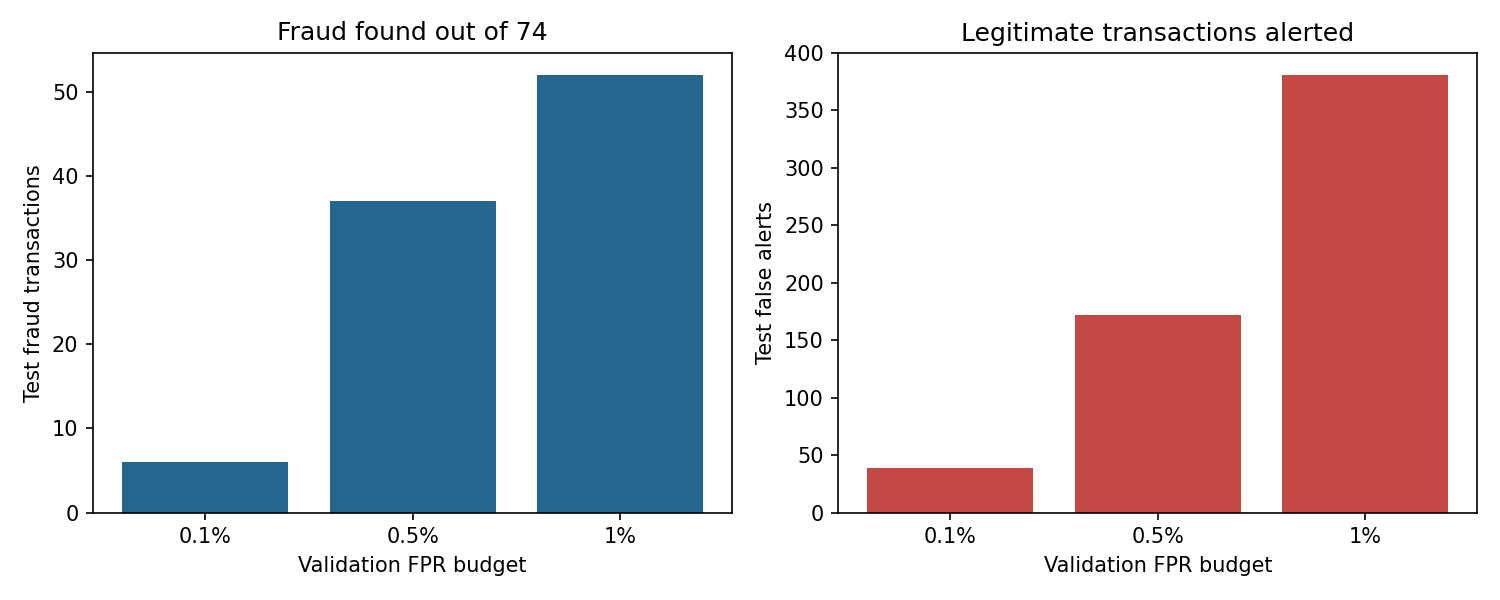

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
labels = ["0.1%", "0.5%", "1%"]
axes[0].bar(labels, policy_table["Test fraud found"], color="#24668d")
axes[0].set_title("Fraud found out of 74")
axes[0].set_xlabel("Validation FPR budget")
axes[0].set_ylabel("Test fraud transactions")
axes[1].bar(labels, policy_table["Test false alerts"], color="#c44945")
axes[1].set_title("Legitimate transactions alerted")
axes[1].set_xlabel("Validation FPR budget")
axes[1].set_ylabel("Test false alerts")
plt.tight_layout()
plt.savefig("figures/08_tradeoff.png", dpi=150)
display(Image(filename="figures/08_tradeoff.png", width=800))
plt.close()

**Chart explanation:** Read both panels together. The rightmost policy catches more fraud, but it also asks investigators to review more legitimate transactions. A taller fraud-found bar alone is not enough to decide a useful operating policy.

## 6. Read the precision-recall curve and PR AUC
Our earlier precision and recall used one cutoff. A **precision-recall (PR) curve** shows them across possible cutoffs.

The horizontal axis is recall: move right to find more of the fraud. The vertical axis is precision: higher means fewer wasted alerts as a fraction of the review queue.

**PR AUC** is the area under this curve. We use trapezoidal integration: connect neighboring points with straight lines and add their areas. It summarizes the ranking on this dataset. Larger is better when comparing the same test set. It is not accuracy and is not precision at our chosen cutoff.

The horizontal reference line is the test fraud rate: the precision level associated with an uninformed ranking. We use trapezoidal PR AUC consistently for both models, so there is one area-summary definition to learn.

**This cell:** Calculate the two PR curves and their areas.

**Files in the next cell:** `results/ranking_comparison.csv`.

`read_csv`, `np.load` and `joblib.load` read files. `to_csv`, `write_text`, `savefig`, `np.savez_compressed` and `joblib.dump` save files. The file map explains what each file contains.

In [10]:
pr_precision, pr_recall, _ = precision_recall_curve(y_test, test_scores)
pr_auc = auc(pr_recall, pr_precision)
test_fraud_rate = y_test.mean()
reference_scores = -one_gaussian.score_samples(X_test_scaled)
reference_precision, reference_recall, _ = precision_recall_curve(y_test, reference_scores)
reference_pr_auc = auc(reference_recall, reference_precision)
ranking = pd.DataFrame({"Model": ["Selected GMM", "One Gaussian"],
    "PR AUC": [float(pr_auc), float(reference_pr_auc)]})
display(ranking)
print(f"Test PR AUC (trapezoidal): {pr_auc:.4f}")
print(f"Test fraud rate: {100*test_fraud_rate:.4f}%")
ranking.to_csv("results/ranking_comparison.csv", index=False)

Test PR AUC (trapezoidal): 0.1496
Test fraud rate: 0.1304%


,Model,PR AUC
0,Selected GMM,0.149619
1,One Gaussian,0.052650


**This cell:** Draw the curves calculated in the previous cell.

**Files in the next cell:** `figures/09_precision_recall.png`.

`read_csv`, `np.load` and `joblib.load` read files. `to_csv`, `write_text`, `savefig`, `np.savez_compressed` and `joblib.dump` save files. The file map explains what each file contains.

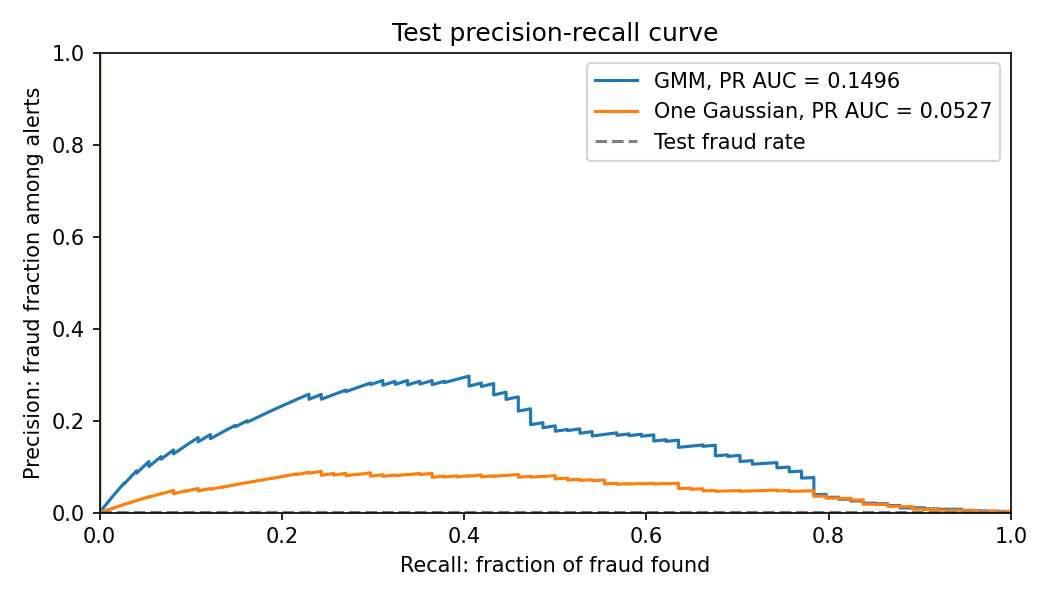

In [11]:
plt.figure(figsize=(7, 4))
plt.plot(pr_recall, pr_precision, label=f"GMM, PR AUC = {pr_auc:.4f}")
plt.plot(reference_recall, reference_precision, label=f"One Gaussian, PR AUC = {reference_pr_auc:.4f}")
plt.axhline(test_fraud_rate, color="gray", linestyle="--", label="Test fraud rate")
plt.xlabel("Recall: fraction of fraud found")
plt.ylabel("Precision: fraud fraction among alerts")
plt.title("Test precision-recall curve")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.savefig("figures/09_precision_recall.png", dpi=150)
display(Image(filename="figures/09_precision_recall.png", width=800))
plt.close()

**Result:** Test PR AUC is approximately **0.1496**. The curve shows how alert quality changes as recall changes. This number does **not** mean we catch 14.96% of fraud; at the default cutoff, recall is 50%.

The conventional PR endpoint at zero recall can have precision 1 even though no transactions are reviewed there. It does not mean our highest-scoring transaction is guaranteed to be fraud.

The one-Gaussian reference has PR AUC about 0.0527 under the same scaler, training rows and test period. The selected GMM ranks fraud better in this run. This is evidence for this split, not a guarantee that more components always help.

## 7. What if investigators can review only 100 transactions?
This is a **capacity rule**: sort the test transactions by score and take exactly the first 100. It differs from a threshold rule, which can produce any number of alerts.

`argsort` gives row positions sorted by score. The minus sign puts larger scores first. `[:100]` keeps the first 100 positions. Stable sorting keeps the existing time order when scores tie.

This is 100 reviews for the **whole test batch**, not a daily review-rate claim.

**This cell:** Sort the scores and count frauds in the first 100 positions.

In [12]:
ranked_positions = np.argsort(-test_scores, kind="stable")
top_100_positions = ranked_positions[:100]
frauds_in_100 = int(y_test[top_100_positions].sum())
precision_at_100 = frauds_in_100 / 100

print("Frauds among the 100 reviewed:", frauds_in_100)
print(f"Precision@100: {100*precision_at_100:.0f}%")

Frauds among the 100 reviewed: 29
Precision@100: 29%


**This cell:** Draw the top-100 counts calculated above.

**Files in the next cell:** `figures/10_capacity.png`.

`read_csv`, `np.load` and `joblib.load` read files. `to_csv`, `write_text`, `savefig`, `np.savez_compressed` and `joblib.dump` save files. The file map explains what each file contains.

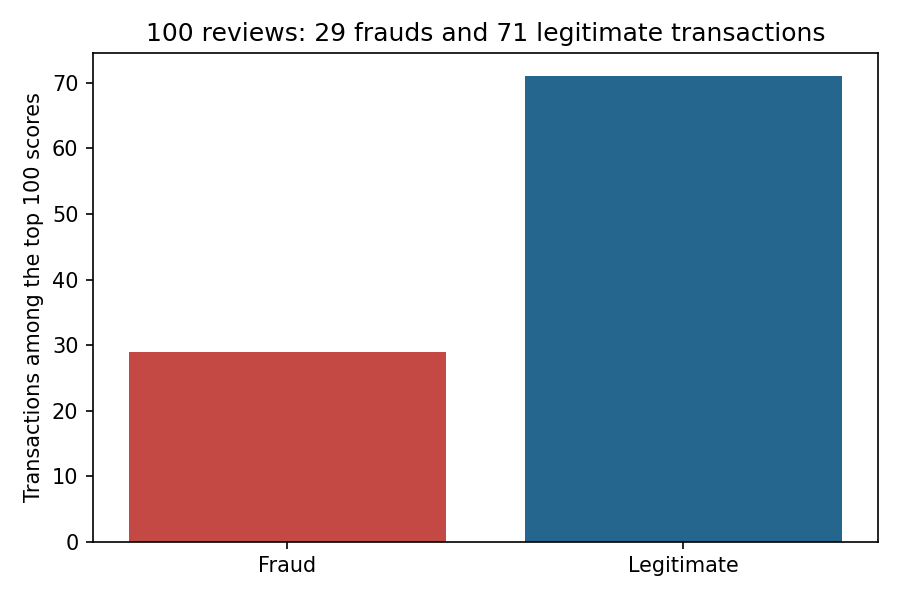

In [13]:
plt.figure(figsize=(6, 4))
plt.bar(["Fraud", "Legitimate"], [frauds_in_100, 100-frauds_in_100], color=["#c44945", "#24668d"])
plt.ylabel("Transactions among the top 100 scores")
plt.title("100 reviews: 29 frauds and 71 legitimate transactions")
plt.tight_layout()
plt.savefig("figures/10_capacity.png", dpi=150)
display(Image(filename="figures/10_capacity.png", width=800))
plt.close()

**Result:** We find 29 frauds among 100 reviews, so **precision@100 = 29%**. The other 71 are legitimate. The default threshold found 37 frauds with 209 reviews, so these two policies have different workloads.

## 8. Review capacities beyond 100
The required headline is precision@100. This small table also shows 50, 200 and 500 reviews, using the same fixed ranking. It adds no new training.

A larger review queue need not have lower precision at every step, because the next block of transactions can contain more or fewer frauds. These capacities apply to the whole test batch.

**This cell:** Sort the scores and count frauds in the first 100 positions.

**Files in the next cell:** `results/review_capacities.csv`.

`read_csv`, `np.load` and `joblib.load` read files. `to_csv`, `write_text`, `savefig`, `np.savez_compressed` and `joblib.dump` save files. The file map explains what each file contains.

In [14]:
capacity_rows = []
for capacity in [50, 100, 200, 500]:
    fraud_found = int(y_test[ranked_positions[:capacity]].sum())
    capacity_rows.append({"Reviews": capacity, "Fraud found": fraud_found,
        "Precision (%)": 100*fraud_found/capacity,
        "Recall (%)": 100*fraud_found/int(y_test.sum())})
capacity_table = pd.DataFrame(capacity_rows)
display(capacity_table)
capacity_table.to_csv("results/review_capacities.csv", index=False)

,Reviews,Fraud found,Precision (%),Recall (%)
0,50,8,16.0,10.810811
1,100,29,29.0,39.189189
2,200,37,18.5,50.000000
3,500,53,10.6,71.621622


**This cell:** Draw the top-100 counts calculated above.

**Files in the next cell:** `figures/12_review_capacities.png`.

`read_csv`, `np.load` and `joblib.load` read files. `to_csv`, `write_text`, `savefig`, `np.savez_compressed` and `joblib.dump` save files. The file map explains what each file contains.

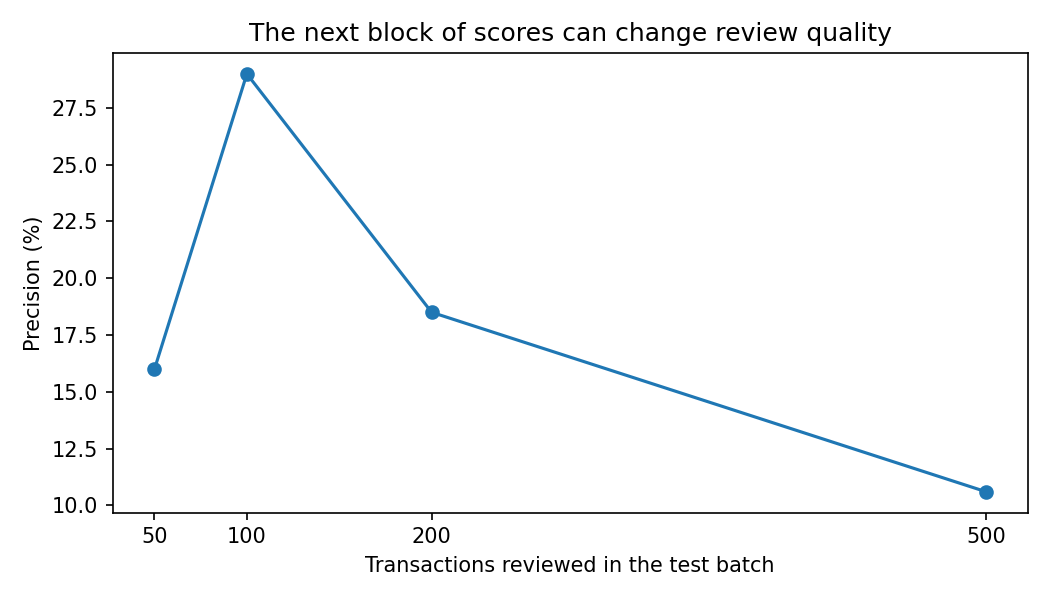

In [15]:
plt.figure(figsize=(7, 4))
plt.plot(capacity_table["Reviews"], capacity_table["Precision (%)"], "o-")
plt.xticks([50, 100, 200, 500])
plt.xlabel("Transactions reviewed in the test batch")
plt.ylabel("Precision (%)")
plt.title("The next block of scores can change review quality")
plt.tight_layout()
plt.savefig("figures/12_review_capacities.png", dpi=150)
display(Image(filename="figures/12_review_capacities.png", width=800))
plt.close()

## 9. Why false alerts and missed fraud occur
This chart compares the two classes' anomaly-score distributions after evaluation. Their overlap explains why a cutoff cannot separate every row correctly.

For display only, `log(1 + max(score, 0))` compresses the long score range. Scores below zero would appear at zero. We do not transform the scores used for ranking or thresholds. Each class has its own density normalization so we compare shapes rather than class counts.

**Files in the next cell:** `figures/13_score_overlap.png`.

`read_csv`, `np.load` and `joblib.load` read files. `to_csv`, `write_text`, `savefig`, `np.savez_compressed` and `joblib.dump` save files. The file map explains what each file contains.

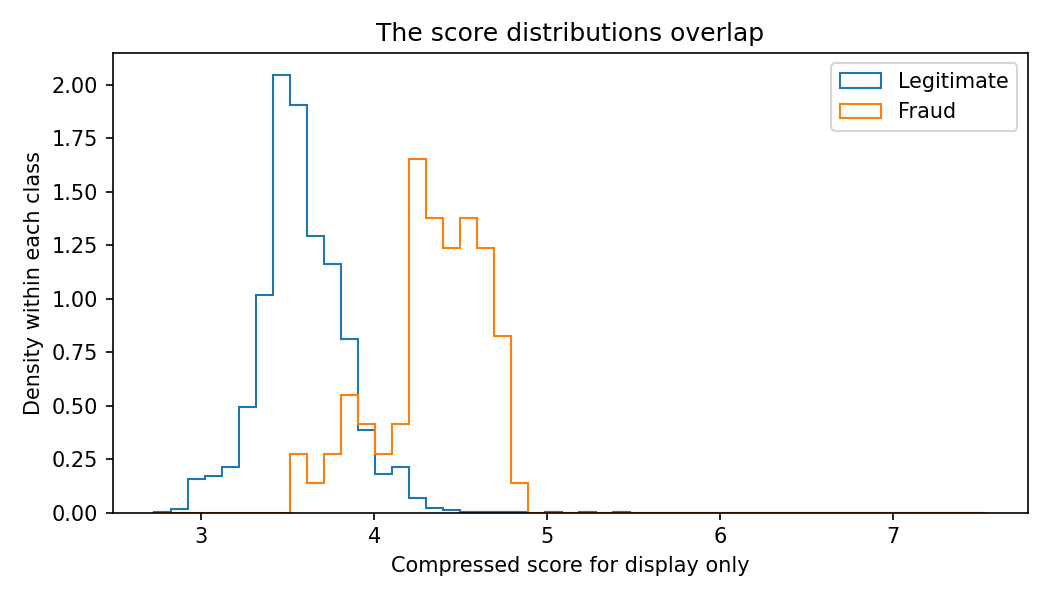

In [16]:
display_scores = np.log1p(np.maximum(test_scores, 0))
bins = np.linspace(display_scores.min(), display_scores.max(), 50)
plt.figure(figsize=(7, 4))
plt.hist(display_scores[y_test == 0], bins=bins, density=True, histtype="step", label="Legitimate")
plt.hist(display_scores[y_test == 1], bins=bins, density=True, histtype="step", label="Fraud")
plt.xlabel("Compressed score for display only")
plt.ylabel("Density within each class")
plt.title("The score distributions overlap")
plt.legend()
plt.tight_layout()
plt.savefig("figures/13_score_overlap.png", dpi=150)
display(Image(filename="figures/13_score_overlap.png", width=800))
plt.close()

## 10. Save results and verify the experiment
The saved rows make the report numbers traceable. Recomputing counts from scores must agree with the summary. These checks are about correct evaluation, not forcing a desired performance value.

A default summary and both model rankings are saved. Software versions and the raw-data checksum identify the run. The test-score file lets us audit calculations; it must not be reused to tune against this held-out period.

**This cell:** Save the true class and two model scores for each test transaction.

**Files in the next cell:** `results/test_scores.csv`.

`read_csv`, `np.load` and `joblib.load` read files. `to_csv`, `write_text`, `savefig`, `np.savez_compressed` and `joblib.dump` save files. The file map explains what each file contains.

In [17]:
pd.DataFrame({"Class": y_test, "GMM score": test_scores,
              "One Gaussian score": reference_scores}).to_csv("results/test_scores.csv", index=False)

**This cell:** Read the earlier quality/settings records and save the default result summary.

**Files in the next cell:** `results/data_quality.json`, `results/model_settings.json`, `results/summary.json`.

`read_csv`, `np.load` and `joblib.load` read files. `to_csv`, `write_text`, `savefig`, `np.savez_compressed` and `joblib.dump` save files. The file map explains what each file contains.

In [18]:
import platform
import sklearn
import matplotlib
quality = json.loads(Path("results/data_quality.json").read_text())
settings = json.loads(Path("results/model_settings.json").read_text())
summary = {
    "raw_rows": quality["raw_rows"], "raw_frauds": quality["raw_frauds"],
    "duplicates_removed": quality["duplicates_removed"],
    "clean_rows": quality["clean_rows"], "clean_frauds": quality["clean_frauds"],
    "selected_K": settings["selected_K"], "default_threshold": default_threshold,
    "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    "recall": float(recall_default), "precision": float(precision_default),
    "test_FPR": float(fpr_default), "PR_AUC": float(pr_auc),
    "one_gaussian_PR_AUC": float(reference_pr_auc),
    "precision_at_100": float(precision_at_100)
}
Path("results/summary.json").write_text(json.dumps(summary, indent=2))

Out[18]: 432


**This cell:** Save the software versions and input checksum so the run can be identified.

**Files in the next cell:** `results/run_info.json`.

`read_csv`, `np.load` and `joblib.load` read files. `to_csv`, `write_text`, `savefig`, `np.savez_compressed` and `joblib.dump` save files. The file map explains what each file contains.

In [19]:
run_info = {"python": platform.python_version(), "numpy": np.__version__,
    "pandas": pd.__version__, "sklearn": sklearn.__version__, "matplotlib": matplotlib.__version__,
    "seed": 42, "raw_sha256": quality["sha256"], "test_rows": len(y_test),
    "test_frauds": int(y_test.sum()), "prediction_rule": "score > threshold"}
Path("results/run_info.json").write_text(json.dumps(run_info, indent=2))

Out[19]: 296


**This cell:** Check that the score lengths and confusion counts agree. An assert stops if a check fails.

In [20]:
assert len(test_scores) == len(y_test)
assert np.isfinite(test_scores).all() and np.isfinite(reference_scores).all()
assert tn + fp + fn + tp == len(y_test)
assert tp + fn == int(y_test.sum())
assert int((test_scores > default_threshold).sum()) == tp + fp
print("Saved final results. Score, count and validation-budget checks passed.")

Saved final results. Score, count and validation-budget checks passed.


## 11. Explain the project in six sentences
1. We want to help people decide which card transactions to review first.
2. We learn normal patterns from 169,893 legitimate training transactions.
3. We use 29 inputs, fit four GMMs, and select K=8 using the smallest training BIC.
4. We give less typical transactions a higher score and choose alert cutoffs using validation data.
5. The default cutoff finds 37 of 74 test frauds with 172 false alerts; the top 100 scores contain 29 frauds.
6. The model makes mistakes, and the data is too limited to claim it will work the same way in a real bank.

## What are the important limits?
- **Unusual does not always mean fraud.** This explains false alerts and missed fraud.
- **Only 74 test frauds.** One different fraud decision changes recall by about 1.35 percentage points.
- **Old, short dataset with hidden feature meanings.** It cannot establish current bank performance. We cannot inspect the provider's original PCA fitting.
- **Simplified model and small K search.** Diagonal covariance misses some relationships, and eight is only the best K we tried.
- **Cleaning assumption.** We remove exact repeated rows without transaction IDs to prove their identity.
- **Future patterns can change.** A validation false-alert budget does not guarantee the same rate later.

## Short literature review
| Source | What we learn | Where we use it |
|---|---|---|
| Dempster, Laird and Rubin (1977) | EM alternates estimated memberships and parameter updates | GMM training |
| Saito and Rehmsmeier (2015) | PR measures help expose false-alert burden with rare positives | Evaluation |
| scikit-learn mixture documentation | GMM settings and AIC/BIC selection | Implementation |
| ULB/Worldline dataset and TensorFlow mirror documentation | Data source and column context | Dataset |

These sources explain our method. Our results come from the run above, not numbers copied from a paper.

## Sources
- [Dempster, Laird and Rubin (1977): EM](https://doi.org/10.1111/j.2517-6161.1977.tb01600.x)
- [Saito and Rehmsmeier (2015): precision-recall evaluation](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0118432)
- [scikit-learn: Gaussian mixtures](https://scikit-learn.org/stable/modules/mixture.html)
- [ULB/Worldline dataset](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)
- [TensorFlow: documented data mirror](https://www.tensorflow.org/tutorials/structured_data/imbalanced_data)
- Supplied course instructions, page 2: Phase 1 evaluates machine learning; the viva assesses each student individually.

The report and slides use these same choices and results. The autoencoder is reserved for Phase 2. See the root `STUDY_GUIDE.md` for a short glossary, worked examples and viva questions.